# Uttarakhand Landslide Susceptibility Mapping

> **Objective:** Map relative landslide susceptibility across Uttarakhand using terrain predictors and machine learning.

---

## 1\. Study Area

The project focuses on Uttarakhand, India, a Himalayan state with complex terrain and substantial variation in elevation, slope, land cover, and accessibility.

<div style="text-align:center; margin:18px 0;">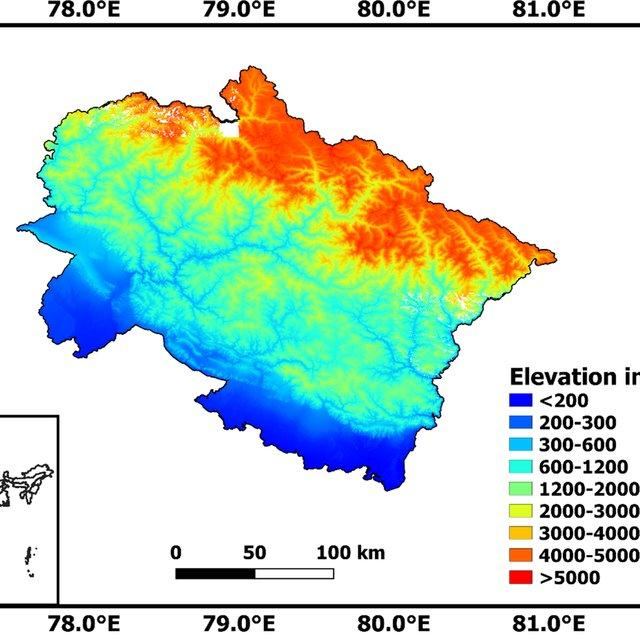</div>

---

&nbsp;

## 2\. Dataset

**11,024 samples** · **8 predictors** · **EPSG:32644**

Sample type             Count   Target

---

Recorded landslides     5,512        1 Background samples      5,512        0

**Predictors:** Elevation · Slope · Aspect · Profile curvature · Plan curvature · Land cover · Distance to road · Distance to river

<div style="text-align:center; margin:18px 0;">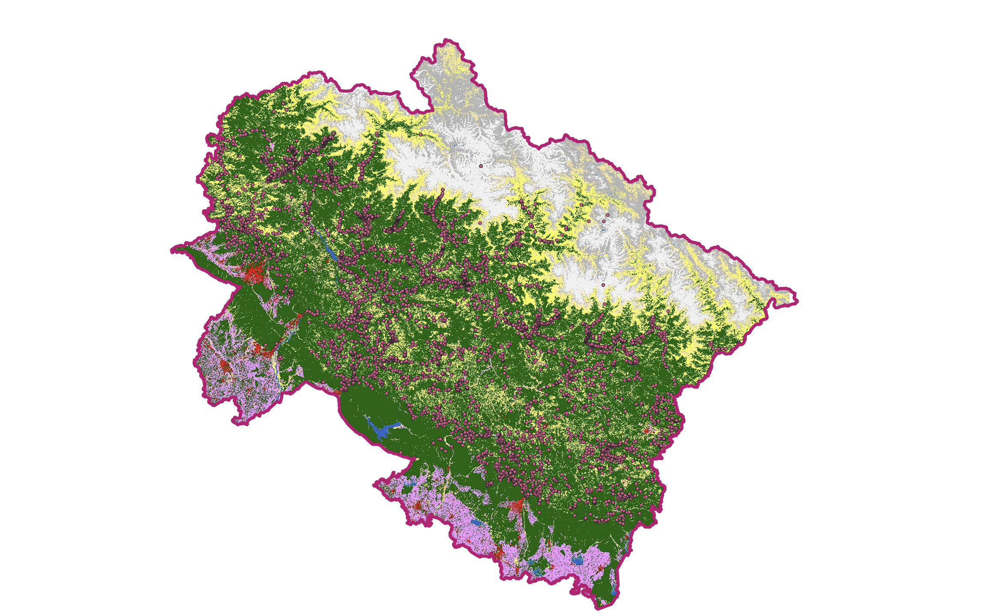</div>

> **Important:** Background samples are unrecorded locations, not confirmed landslide-free locations. Inventory coverage and reporting may be biased toward accessible areas.

---

&nbsp;

## 3\. Spatial Split

**10 km grid-based split** · `test_size=0.20` · `random_state=42`

Partition     Samples   Background   Landslide

---

Training        8,723        4,399       4,324 Test            2,301        1,113       1,188

- Training groups: **477**  
- Test groups: **120**  
- Shared groups: **0**

Spatial grouping reduces leakage between groups, but does not guarantee a minimum 10 km distance between every train and test point.

---

## 4\. Model Selection

Models compared: **XGBoost · CatBoost · Random Forest**

Model              Spatial CV ROC-AUC

---

XGBoost           **0.9497 ± 0.0048** CatBoost              0.9486 ± 0.0050 Random Forest         0.9479 ± 0.0044

**Selected model: XGBoost**, which had the highest reported mean ROC-AUC among the tested models. The differences are small and should not be overstated.

**Selected configuration:** 400 estimators · max depth 4 · learning rate 0.03 · `min_child_weight=5` · `subsample=0.8` · `colsample_bytree=0.8` · `reg_lambda=2` · seed 42\.

`land_cover` is one-hot encoded; the seven remaining predictors pass through the preprocessing pipeline.

---

&nbsp;

## 5\. Held-Out Spatial Test Results

Metric                Training         Test

---

Accuracy                   \---       0.8818 Balanced accuracy          \---       0.8815 ROC-AUC                 0.9638   **0.9496** Average precision       0.9616   **0.9492**

**Test confusion matrix** (threshold \= 0.5)

Actual ↓ / Predicted →     Background   Landslide

---

Background                        970         143 Landslide                         129       1,059

The local test results use the local 10 km split and should not be assumed to match the earlier Colab cross-validation folds.

---

&nbsp;

## 6\. Susceptibility Maps

### Continuous susceptibility

<div style="text-align:center; margin:18px 0;">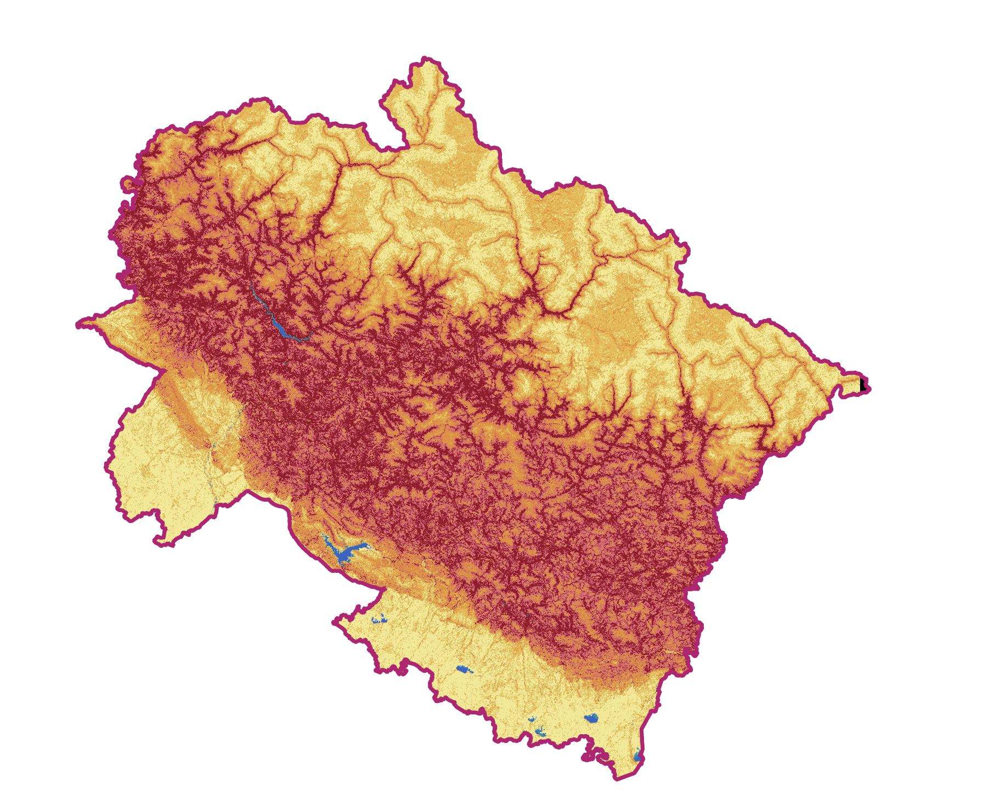</div>

The continuous raster is `uknd_xgboost_susceptibility.tif` (Float32, EPSG:32644; 11,759 × 10,715 cells). It contains 66,012,548 valid predictions and 59,985,137 NoData cells. Valid scores range from approximately **0.000820 to 0.998518**, with a mean of **0.182532**.

These scores are model outputs and **have not been calibrated as real-world event probabilities**.

### 3D visualization for achieved Susceptibility Map with XGBoost

<div style="text-align:center; margin:18px 0;">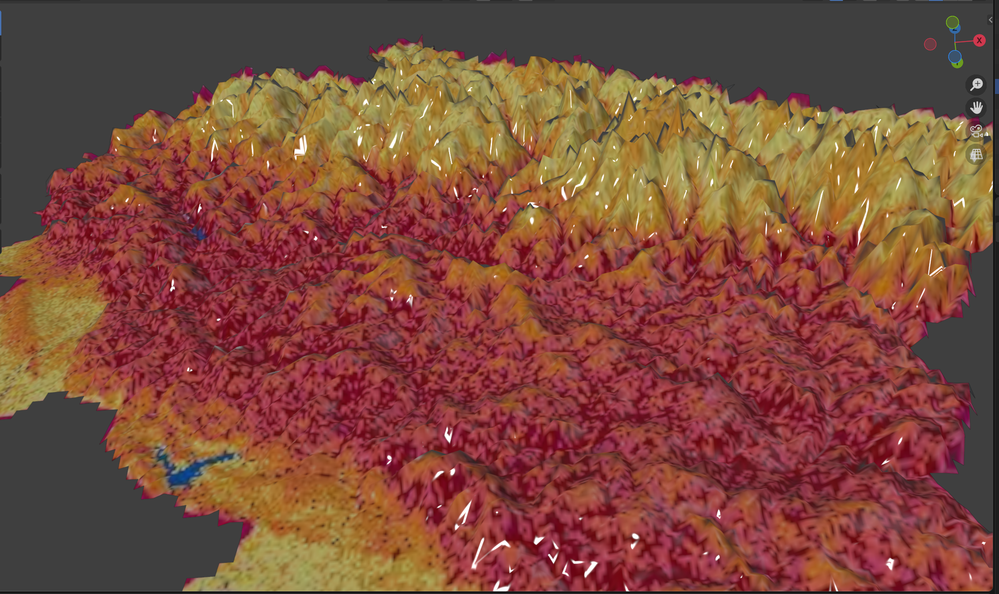</div>

—

&nbsp;

<div style="text-align:center; margin:18px 0;">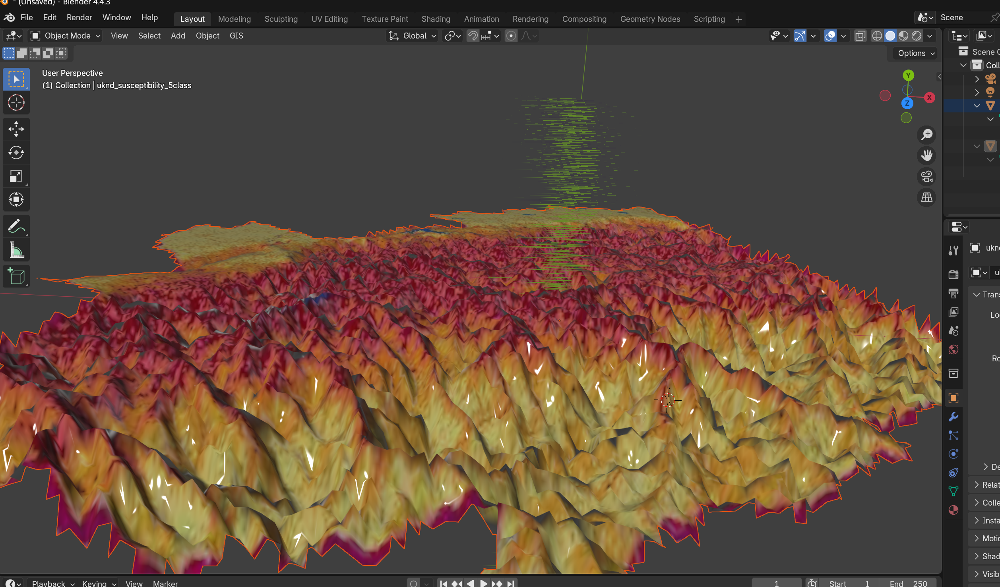</div>

Five-class raster: `uknd_susceptibility_5class.tif` (UInt8; class `0` \= NoData).

```
Class Label       Score interval
```

&nbsp;

---

```
    1 Very Low    ≤ 0.005305
    2 Low         \> 0.005305 to 0.020048
    3 Moderate    \> 0.020048 to 0.116785
    4 High        \> 0.116785 to 0.346057
    5 Very High   \> 0.346057
```

&nbsp;

Classes use percentile-based cut points, so they represent **relative map classes**, not official hazard categories.

---

## 7\. Notes

- **Background uncertainty:** unrecorded does not mean landslide-free.  
- **Inventory bias:** remote or sparsely inhabited terrain may have fewer recorded events.  
- **Score interpretation:** outputs are not calibrated event probabilities.

---

## Key Takeaway

XGBoost achieved the highest reported spatial cross-validation ROC-AUC among the tested models and produced continuous and five-class susceptibility maps. Results should be interpreted as **relative susceptibility**, considering inventory and background-sampling limitations.

In [21]:
# @title
from pathlib import Path
from IPython.display import display, HTML
import base64
import mimetypes
import re
import html

visuals = Path(
    "/content/drive/MyDrive/Colab Notebooks/data/uknd/visuals"
)

md_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/data/uknd/"
    "uknd_colab_model_documentation.md"
)

content = md_path.read_text(encoding="utf-8")

image_widths = {
    "Elevation Map Uttarakhand.jpg": 500,
    "Uttarakhand_historical_landslide_datapoints_with_landcover.png": 550,
    "Uttarakhand_landslide_susceptibility_view.png": 550,
    "UK_landslide__susceptibility-3D_view.png": 500,
    "Uk_landslide_susceptibility_3D_view-2.png": 500,
}

# Replace each Markdown image with an embedded HTML image
for filename, width in image_widths.items():
    image_path = visuals / filename

    if not image_path.is_file():
        print(f"Missing image: {filename}")
        continue

    mime = mimetypes.guess_type(filename)[0] or "image/png"
    encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
    data_url = f"data:{mime};base64,{encoded}"

    # Support spaces and URL-encoded spaces in Markdown paths
    escaped_filename = re.escape(filename).replace(r"\ ", r"(?: |%20)")
    pattern = re.compile(
        r"!\[([^\]]*)\]\([^)]*" + escaped_filename + r"\)"
    )

    image_html = (
        '<div style="text-align:center; margin:18px 0;">'
        f'<img src="{data_url}" '
        f'alt="{html.escape(filename, quote=True)}" '
        f'width="{width}" '
        f'style="display:block; width:{width}px; max-width:100%; '
        'height:auto; margin:0 auto;">'
        '</div>'
    )

    content, count = pattern.subn(
        lambda match: image_html,
        content
    )

# Render the Markdown sections and embedded images as HTML
# Markdown conversion is handled first, then custom image tags are inserted.
from IPython.display import Markdown

# Keep the Markdown content and display the resized images separately
display(Markdown(
    re.sub(r"!\[([^\]]*)\]\([^)]*\)", "", content)
))

In [1]:
# @title

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/data/uknd/combined_training.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (11024, 20)

Column names:
['landslide_id', 'x_utm44n', 'y_utm44n', 'elevation', 'slope', 'aspect', 'profile_curvature', 'plan_curvature', 'land_cover', 'distance_to_road', 'distance_to_river', 'all_predictors_valid', 'target', 'sample_type', 'sampling_method', 'buffer_m', 'random_seed', 'background_id', 'block_x', 'block_y']

First five rows:


,landslide_id,x_utm44n,y_utm44n,elevation,slope,aspect,profile_curvature,plan_curvature,land_cover,distance_to_road,distance_to_river,all_predictors_valid,target,sample_type,sampling_method,buffer_m,random_seed,background_id,block_x,block_y
0,1.0,411561.744933,3.223315e+06,675.523682,35.013336,158.772202,0.001266,0.008587,10.0,28.377802,1289.864014,True,1,recorded_landslide,inventory,NaN,42,NaN,NaN,NaN
1,2.0,409924.624427,3.223821e+06,586.073669,35.286541,237.864914,-0.001432,-0.014475,60.0,533.170471,102.317619,True,1,recorded_landslide,inventory,NaN,42,NaN,NaN,NaN
2,3.0,398683.311183,3.224237e+06,580.407410,37.907085,10.123124,-0.005924,-0.004014,10.0,7264.717285,221.637726,True,1,recorded_landslide,inventory,NaN,42,NaN,NaN,NaN
3,4.0,419679.544788,3.224223e+06,377.183685,35.075836,100.516869,-0.003990,-0.001700,10.0,380.728149,255.400223,True,1,recorded_landslide,inventory,NaN,42,NaN,NaN,NaN
4,5.0,420305.097369,3.224374e+06,657.918152,35.614788,226.221252,-0.000416,0.001384,30.0,394.237000,368.911438,True,1,recorded_landslide,inventory,NaN,42,NaN,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11024 entries, 0 to 11023
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   landslide_id          5512 non-null   float64
 1   x_utm44n              11024 non-null  float64
 2   y_utm44n              11024 non-null  float64
 3   elevation             11024 non-null  float64
 4   slope                 11024 non-null  float64
 5   aspect                11024 non-null  float64
 6   profile_curvature     11024 non-null  float64
 7   plan_curvature        11024 non-null  float64
 8   land_cover            11024 non-null  float64
 9   distance_to_road      11024 non-null  float64
 10  distance_to_river     11024 non-null  float64
 11  all_predictors_valid  5512 non-null   object 
 12  target                11024 non-null  int64  
 13  sample_type           11024 non-null  object 
 14  sampling_method       11024 non-null  object 
 1

In [2]:
# @title

import numpy as np
import pandas as pd

predictors = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "land_cover",
    "distance_to_road",
    "distance_to_river",
]

# 1. Class balance
print("Target distribution:")
print(df["target"].value_counts().sort_index())
print("\nSample types:")
print(df["sample_type"].value_counts())

# 2. Predictor summary
print("\nPredictor statistics:")
display(df[predictors].describe().T.round(3))

# 3. Land-cover categories
print("\nLand-cover values and frequencies:")
display(df["land_cover"].value_counts().sort_index().to_frame("count"))

# 4. Coordinate and predictor checks
print("\nDuplicate coordinates:", df.duplicated(
    subset=["x_utm44n", "y_utm44n"]
).sum())

print("Non-finite predictor values:",
      (~np.isfinite(df[predictors].to_numpy(dtype=float))).sum())

print("Invalid slope values:",
      ((df["slope"] < 0) | (df["slope"] > 90)).sum())

print("Invalid aspect values:",
      ((df["aspect"] < 0) | (df["aspect"] > 360)).sum())

print("Negative road distances:",
      (df["distance_to_road"] < 0).sum())

print("Negative river distances:",
      (df["distance_to_river"] < 0).sum())


Target distribution:
target
0    5512
1    5512
Name: count, dtype: int64

Sample types:
sample_type
recorded_landslide       5512
background_unrecorded    5512
Name: count, dtype: int64

Predictor statistics:


,count,mean,std,min,25%,50%,75%,max
elevation,11024.0,1823.114,1315.480,193.263,1023.128,1459.763,2034.446,7068.162
slope,11024.0,28.898,12.822,0.020,21.629,31.011,37.821,85.540
aspect,11024.0,181.346,97.917,0.040,102.652,182.539,261.258,359.985
profile_curvature,11024.0,-0.001,0.004,-0.025,-0.002,-0.000,0.001,0.029
plan_curvature,11024.0,-0.000,0.006,-0.033,-0.003,-0.000,0.003,0.035
land_cover,11024.0,25.522,21.067,10.000,10.000,10.000,30.000,100.000
distance_to_road,11024.0,961.328,2015.093,0.000,28.378,141.889,811.625,17571.543
distance_to_river,11024.0,912.327,760.815,0.000,261.630,710.012,1423.423,4967.088



Land-cover values and frequencies:


,count
land_cover,
10.0,5916
20.0,11
30.0,2868
40.0,380
50.0,435
60.0,696
70.0,464
80.0,32
90.0,2



Duplicate coordinates: 94
Non-finite predictor values: 0
Invalid slope values: 0
Invalid aspect values: 0
Negative road distances: 0
Negative river distances: 0


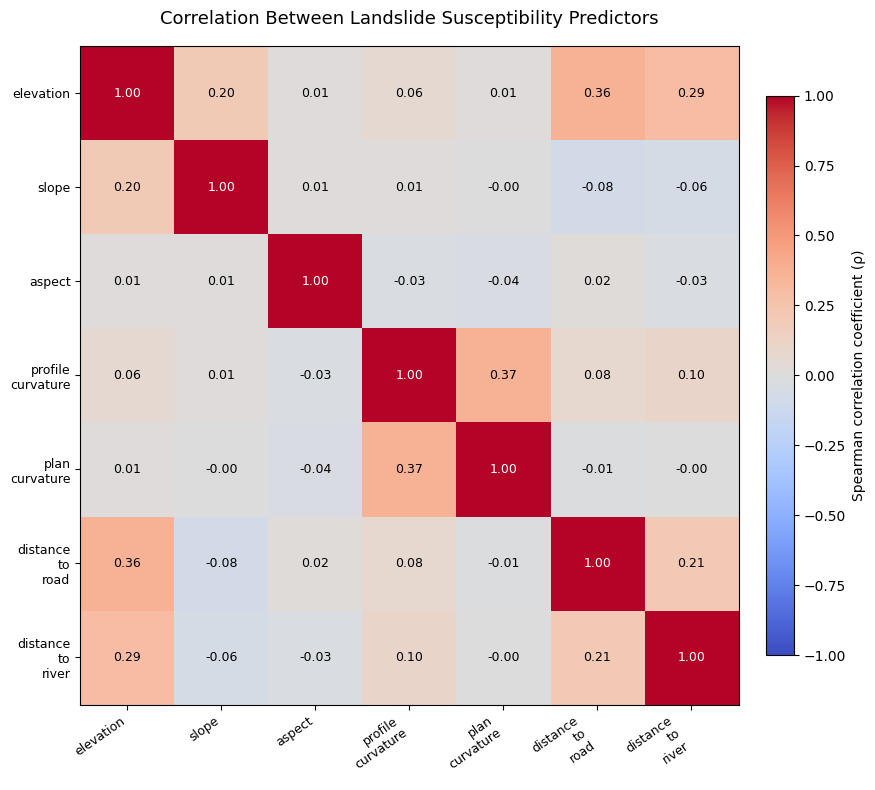

In [3]:
# @title

import numpy as np
import matplotlib.pyplot as plt

correlation_features = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "distance_to_road",
    "distance_to_river",
]

# Calculate Spearman rank correlations
corr = df[correlation_features].corr(method="spearman")

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

# Axis labels
labels = [feature.replace("_", "\n") for feature in correlation_features]
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

# Annotate correlation values
for i in range(len(correlation_features)):
    for j in range(len(correlation_features)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.6 else "black"
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9
        )

# Colour bar and title
cbar = fig.colorbar(image, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Spearman correlation coefficient (ρ)")

ax.set_title(
    "Correlation Between Landslide Susceptibility Predictors",
    fontsize=13,
    pad=16
)

fig.tight_layout()
plt.show()


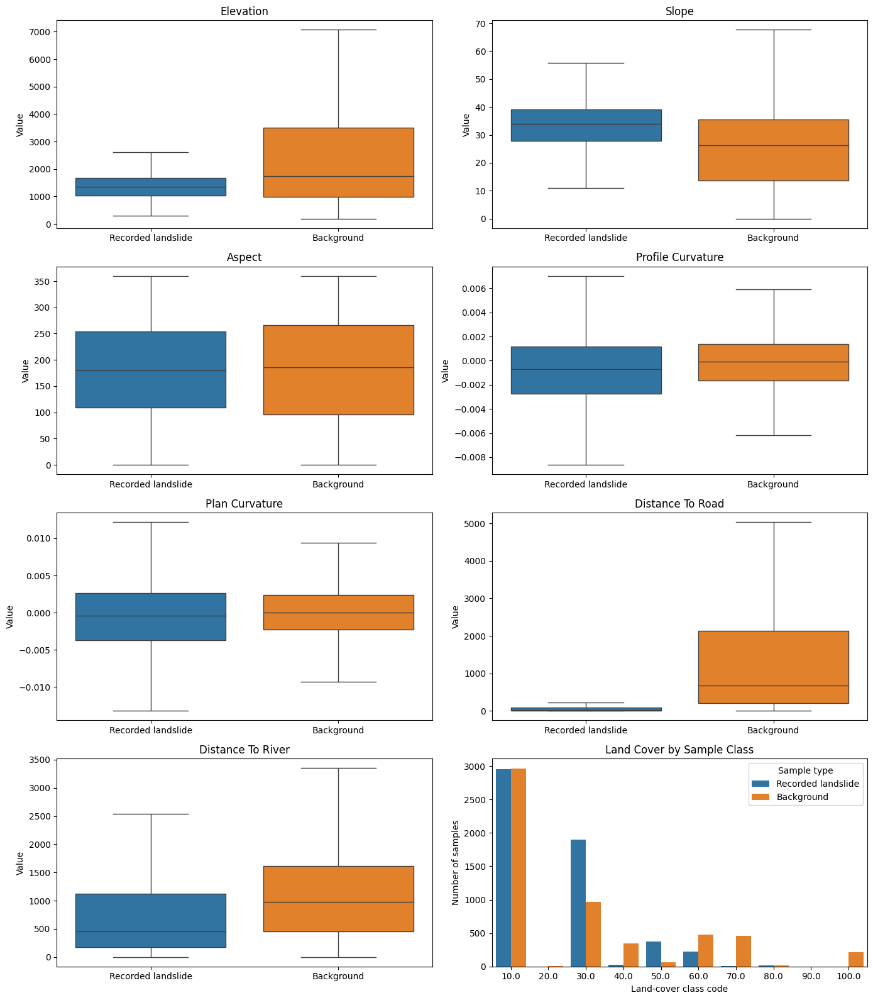

In [4]:
# @title

import matplotlib.pyplot as plt
import seaborn as sns

# Keep land cover separate because it is categorical
continuous_features = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "distance_to_road",
    "distance_to_river",
]

plot_df = df.copy()
plot_df["class_label"] = plot_df["target"].map({
    0: "Background",
    1: "Recorded landslide"
})

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, feature in enumerate(continuous_features):
    sns.boxplot(
        data=plot_df,
        x="class_label",
        y=feature,
        hue="class_label",
        legend=False,
        showfliers=False,
        ax=axes[i]
    )
    axes[i].set_title(feature.replace("_", " ").title())
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Value")

# Land-cover distribution by class
sns.countplot(
    data=plot_df,
    x="land_cover",
    hue="class_label",
    order=sorted(plot_df["land_cover"].unique()),
    ax=axes[7]
)
axes[7].set_title("Land Cover by Sample Class")
axes[7].set_xlabel("Land-cover class code")
axes[7].set_ylabel("Number of samples")
axes[7].legend(title="Sample type")

plt.tight_layout()
plt.show()


In [5]:
# @title

continuous_features = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "distance_to_road",
    "distance_to_river",
]

# Calculate statistics separately for each target class
background_stats = (
    df.loc[df["target"] == 0, continuous_features]
    .agg(["median", "mean"])
    .T
    .add_suffix("_background")
)

landslide_stats = (
    df.loc[df["target"] == 1, continuous_features]
    .agg(["median", "mean"])
    .T
    .add_suffix("_landslide")
)

summary = background_stats.join(landslide_stats)

display(summary.round(3))


,median_background,mean_background,median_landslide,mean_landslide
elevation,1733.110,2266.715,1348.431,1379.513
slope,26.339,24.768,33.937,33.029
aspect,186.085,181.986,179.999,180.705
profile_curvature,-0.000,-0.000,-0.001,-0.001
plan_curvature,0.000,0.000,-0.000,-0.001
distance_to_road,681.363,1763.094,28.378,159.562
distance_to_river,983.445,1096.133,454.045,728.521


In [6]:
# @title

import numpy as np
import pandas as pd

BLOCK_SIZE_M = 10_000

# Work with a copy; preserve the original dataframe
spatial_df = df.copy()

# Create a consistent 10 km grid anchored to the dataset extent
x_origin = np.floor(spatial_df["x_utm44n"].min() / BLOCK_SIZE_M) * BLOCK_SIZE_M
y_origin = np.floor(spatial_df["y_utm44n"].min() / BLOCK_SIZE_M) * BLOCK_SIZE_M

spatial_df["spatial_x"] = np.floor(
    (spatial_df["x_utm44n"] - x_origin) / BLOCK_SIZE_M
).astype(int)

spatial_df["spatial_y"] = np.floor(
    (spatial_df["y_utm44n"] - y_origin) / BLOCK_SIZE_M
).astype(int)

spatial_df["spatial_group"] = (
    spatial_df["spatial_x"].astype(str)
    + "_"
    + spatial_df["spatial_y"].astype(str)
)

# Count samples of each class in each group
group_counts = pd.crosstab(
    spatial_df["spatial_group"],
    spatial_df["target"]
).rename(columns={0: "background", 1: "landslide"})

group_counts["total"] = (
    group_counts.get("background", 0)
    + group_counts.get("landslide", 0)
)

print("Number of occupied spatial groups:", len(group_counts))
print("\nGroups containing each class:")
print("Both classes:", ((group_counts["background"] > 0) &
                         (group_counts["landslide"] > 0)).sum())
print("Landslide only:", ((group_counts["landslide"] > 0) &
                          (group_counts["background"] == 0)).sum())
print("Background only:", ((group_counts["background"] > 0) &
                           (group_counts["landslide"] == 0)).sum())

print("\nSamples per spatial group:")
display(group_counts.describe().round(1))

print("\nLargest groups:")
display(group_counts.sort_values("total", ascending=False).head(10))


Number of occupied spatial groups: 597

Groups containing each class:
Both classes: 309
Landslide only: 0
Background only: 288

Samples per spatial group:


target,background,landslide,total
count,597.0,597.0,597.0
mean,9.2,9.2,18.5
std,2.5,16.0,16.6
min,1.0,0.0,1.0
25%,10.0,0.0,10.0
50%,10.0,1.0,11.0
75%,10.0,12.0,22.0
max,11.0,119.0,129.0



Largest groups:


target,background,landslide,total
spatial_group,,,
15_18,10,119,129
6_24,10,109,119
10_21,10,105,115
8_25,10,86,96
9_19,10,74,84
22_14,10,74,84
23_9,10,74,84
18_15,10,67,77
7_25,10,66,76


In [7]:
# @title

# Number of positive records concentrated in the largest groups
positive_by_group = (
    spatial_df.groupby("spatial_group")["target"]
    .agg(
        total_samples="size",
        positive_samples="sum"
    )
    .sort_values("positive_samples", ascending=False)
)

positive_by_group["positive_share_pct"] = (
    positive_by_group["positive_samples"] / 5512 * 100
)

for n in [5, 10, 20, 50]:
    share = (
        positive_by_group["positive_samples"]
        .head(n)
        .sum() / 5512 * 100
    )
    print(f"Top {n} groups contain {share:.2f}% of positive records")

print("\nLargest positive groups:")
display(positive_by_group.head(15).round(2))


Top 5 groups contain 8.94% of positive records
Top 10 groups contain 15.20% of positive records
Top 20 groups contain 24.67% of positive records
Top 50 groups contain 46.23% of positive records

Largest positive groups:


,total_samples,positive_samples,positive_share_pct
spatial_group,,,
15_18,129,119,2.16
6_24,119,109,1.98
10_21,115,105,1.90
8_25,96,86,1.56
9_19,84,74,1.34
22_14,84,74,1.34
23_9,84,74,1.34
18_15,77,67,1.22
7_25,76,66,1.20


In [8]:
# @title

import numpy as np
import pandas as pd

BLOCK_SIZE_M = 10_000

# Use a separate copy; do not modify the original dataset.
spatial_df = df.copy()

# Anchor the grid consistently to the projected coordinate system.
x_origin = np.floor(spatial_df["x_utm44n"].min() / BLOCK_SIZE_M) * BLOCK_SIZE_M
y_origin = np.floor(spatial_df["y_utm44n"].min() / BLOCK_SIZE_M) * BLOCK_SIZE_M

spatial_df["block_x"] = np.floor(
    (spatial_df["x_utm44n"] - x_origin) / BLOCK_SIZE_M
).astype(int)

spatial_df["block_y"] = np.floor(
    (spatial_df["y_utm44n"] - y_origin) / BLOCK_SIZE_M
).astype(int)

spatial_df["spatial_group"] = (
    spatial_df["block_x"].astype(str)
    + "_"
    + spatial_df["block_y"].astype(str)
)

# Summarize groups
group_summary = (
    spatial_df.groupby("spatial_group")
    .agg(
        samples=("target", "size"),
        positives=("target", "sum"),
        unique_coordinates=(
            "x_utm44n",
            "nunique"
        )
    )
)

group_summary["background"] = (
    spatial_df.groupby("spatial_group")["target"]
    .apply(lambda s: (s == 0).sum())
)

print("Occupied spatial groups:", len(group_summary))
print("Groups with at least 5 positives:",
      (group_summary["positives"] >= 5).sum())
print("Groups with both classes:",
      ((group_summary["positives"] > 0) &
       (group_summary["background"] > 0)).sum())

print("\nPositive samples per group:")
display(group_summary["positives"].describe().round(2))

print("\nLargest groups:")
display(group_summary.sort_values("positives", ascending=False).head(10))


Occupied spatial groups: 597
Groups with at least 5 positives: 233
Groups with both classes: 309

Positive samples per group:


,positives
count,597.00
mean,9.23
std,16.04
min,0.00
25%,0.00
50%,1.00
75%,12.00
max,119.00



Largest groups:


,samples,positives,unique_coordinates,background
spatial_group,,,,
15_18,129,119,127,10
6_24,119,109,119,10
10_21,115,105,115,10
8_25,96,86,96,10
9_19,84,74,84,10
22_14,84,74,82,10
23_9,84,74,83,10
18_15,77,67,77,10
7_25,76,66,76,10


In [9]:
# @title

from sklearn.model_selection import GroupShuffleSplit

# Eight predictor variables only
predictors = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "land_cover",
    "distance_to_road",
    "distance_to_river",
]

X = spatial_df[predictors].copy()
y = spatial_df["target"].astype(int).copy()
groups = spatial_df["spatial_group"]

# Hold out complete spatial groups
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training groups:", len(train_groups))
print("Testing groups:", len(test_groups))
print("Overlapping groups:", len(train_groups & test_groups))

print("\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\nTesting class counts:")
print(y_test.value_counts().sort_index())

assert train_groups.isdisjoint(test_groups)
assert set(y_train.unique()) == {0, 1}


Training rows: 8641
Testing rows: 2383
Training groups: 477
Testing groups: 120
Overlapping groups: 0

Training class counts:
target
0    4377
1    4264
Name: count, dtype: int64

Testing class counts:
target
0    1135
1    1248
Name: count, dtype: int64


In [12]:
# @title

from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
)
import pandas as pd

def evaluate_model(model, X, y, dataset_name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]

    print(f"\n{'=' * 60}")
    print(f"{dataset_name} EVALUATION")
    print(f"{'=' * 60}")

    print(f"Samples: {len(y)}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y, y_pred):.4f}")
    print(f"Accuracy:          {accuracy_score(y, y_pred):.4f}")
    print(f"ROC-AUC:           {roc_auc_score(y, y_prob):.4f}")
    print(f"Average precision: {average_precision_score(y, y_prob):.4f}")

    print("\nClassification report:")
    print(classification_report(
        y,
        y_pred,
        labels=[0, 1],
        target_names=["Background", "Recorded landslide"],
        digits=4,
        zero_division=0,
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y, y_pred, labels=[0, 1]))


# Evaluate both datasets using the same fitted model
evaluate_model(rf_model, X_train, y_train, "TRAINING SET")
evaluate_model(rf_model, X_test, y_test, "TEST SET")



TRAINING SET EVALUATION
Samples: 8641
Balanced accuracy: 0.9777
Accuracy:          0.9775
ROC-AUC:           0.9987
Average precision: 0.9987

Classification report:
                    precision    recall  f1-score   support

        Background     0.9861    0.9694    0.9776      4377
Recorded landslide     0.9691    0.9859    0.9774      4264

          accuracy                         0.9775      8641
         macro avg     0.9776    0.9777    0.9775      8641
      weighted avg     0.9777    0.9775    0.9775      8641

Confusion matrix:
[[4243  134]
 [  60 4204]]

TEST SET EVALUATION
Samples: 2383
Balanced accuracy: 0.8564
Accuracy:          0.8552
ROC-AUC:           0.9316
Average precision: 0.9318

Classification report:
                    precision    recall  f1-score   support

        Background     0.8270    0.8802    0.8528      1135
Recorded landslide     0.8843    0.8325    0.8576      1248

          accuracy                         0.8552      2383
         macro avg  

In [13]:
# @title

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
)

rf_constrained = Pipeline(
    steps=[
        ("preprocessor", clone(rf_model.named_steps["preprocessor"])),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=18,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )),
    ]
)

rf_constrained.fit(X_train, y_train)

def evaluate_compact(model, X, y, name):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]

    return {
        "Dataset": name,
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob),
        "Average precision": average_precision_score(y, prob),
    }

comparison = pd.DataFrame([
    evaluate_compact(rf_model, X_train, y_train, "Baseline — Train"),
    evaluate_compact(rf_model, X_test, y_test, "Baseline — Test"),
    evaluate_compact(rf_constrained, X_train, y_train, "Constrained — Train"),
    evaluate_compact(rf_constrained, X_test, y_test, "Constrained — Test"),
])

display(comparison.round(4))


,Dataset,Balanced accuracy,ROC-AUC,Average precision
0,Baseline — Train,0.9777,0.9987,0.9987
1,Baseline — Test,0.8564,0.9316,0.9318
2,Constrained — Train,0.9375,0.9870,0.9867
3,Constrained — Test,0.8530,0.9312,0.9324


In [14]:
# @title
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone
import pandas as pd

cv = GroupKFold(n_splits=5)

models = {
    "Baseline RF": rf_model,
    "Constrained RF": rf_constrained,
}

results = []

for name, model in models.items():
    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        groups=spatial_df.loc[X_train.index, "spatial_group"],
        cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
        },
        n_jobs=-1,
        return_train_score=True,
    )

    results.append({
        "Model": name,
        "CV train ROC-AUC": scores["train_roc_auc"].mean(),
        "CV validation ROC-AUC": scores["test_roc_auc"].mean(),
        "CV validation ROC-AUC SD": scores["test_roc_auc"].std(),
        "CV validation balanced accuracy": scores[
            "test_balanced_accuracy"
        ].mean(),
        "CV validation average precision": scores[
            "test_average_precision"
        ].mean(),
    })

display(pd.DataFrame(results).round(4))

,Model,CV train ROC-AUC,CV validation ROC-AUC,CV validation ROC-AUC SD,CV validation balanced accuracy,CV validation average precision
0,Baseline RF,0.9988,0.9472,0.0042,0.8738,0.9400
1,Constrained RF,0.9872,0.9479,0.0044,0.8736,0.9414


In [15]:
%pip install -q xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00


In [16]:
# @title
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    average_precision_score,
)
import pandas as pd
import numpy as np

# Ensure land_cover is categorical for CatBoost.
X_train_boost = X_train.copy()
X_test_boost = X_test.copy()

for data in [X_train_boost, X_test_boost]:
    data["land_cover"] = data["land_cover"].astype(str)

groups_train = spatial_df.loc[
    X_train.index, "spatial_group"
]

cv = GroupKFold(n_splits=5)

# Models compatible with sklearn's cloning mechanism.
models = {
    "Constrained RF": rf_constrained,

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.03,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    ),
}

scoring = {
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision",
}

results = []

# 1. Cross-validation for Random Forest and XGBoost.
for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=True,
    )

    results.append({
        "Model": name,
        "Train ROC-AUC": scores["train_roc_auc"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV ROC-AUC SD": scores["test_roc_auc"].std(),
        "CV Balanced Accuracy":
            scores["test_balanced_accuracy"].mean(),
        "CV Average Precision":
            scores["test_average_precision"].mean(),
    })

# 2. Manual spatial cross-validation for CatBoost.
# This avoids sklearn.clone() for CatBoost.
catboost_splits = list(cv.split(
    X_train_boost, y_train, groups=groups_train
))

catboost_train_auc = []
catboost_val_auc = []
catboost_val_balanced_acc = []
catboost_val_ap = []

for fold, (train_idx, val_idx) in enumerate(catboost_splits, start=1):
    X_fold_train = X_train_boost.iloc[train_idx]
    X_fold_val = X_train_boost.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    model = CatBoostClassifier(
        iterations=600,
        depth=5,
        learning_rate=0.03,
        loss_function="Logloss",
        verbose=0,
        random_seed=42,
        thread_count=-1,
        cat_features=["land_cover"],
    )

    model.fit(X_fold_train, y_fold_train)

    train_prob = model.predict_proba(X_fold_train)[:, 1]
    val_prob = model.predict_proba(X_fold_val)[:, 1]
    val_pred = model.predict(X_fold_val).ravel()

    catboost_train_auc.append(
        roc_auc_score(y_fold_train, train_prob)
    )
    catboost_val_auc.append(
        roc_auc_score(y_fold_val, val_prob)
    )
    catboost_val_balanced_acc.append(
        balanced_accuracy_score(y_fold_val, val_pred)
    )
    catboost_val_ap.append(
        average_precision_score(y_fold_val, val_prob)
    )

    print(
        f"CatBoost fold {fold}/5 complete | "
        f"Validation ROC-AUC: {catboost_val_auc[-1]:.4f}"
    )

results.append({
    "Model": "CatBoost",
    "Train ROC-AUC": np.mean(catboost_train_auc),
    "CV ROC-AUC": np.mean(catboost_val_auc),
    "CV ROC-AUC SD": np.std(catboost_val_auc, ddof=1),
    "CV Balanced Accuracy": np.mean(catboost_val_balanced_acc),
    "CV Average Precision": np.mean(catboost_val_ap),
})

# 3. Compare models.
comparison = pd.DataFrame(results).sort_values(
    "CV ROC-AUC", ascending=False
)

display(comparison.round(4))

CatBoost fold 1/5 complete | Validation ROC-AUC: 0.9492
CatBoost fold 2/5 complete | Validation ROC-AUC: 0.9438
CatBoost fold 3/5 complete | Validation ROC-AUC: 0.9435
CatBoost fold 4/5 complete | Validation ROC-AUC: 0.9517
CatBoost fold 5/5 complete | Validation ROC-AUC: 0.9550


,Model,Train ROC-AUC,CV ROC-AUC,CV ROC-AUC SD,CV Balanced Accuracy,CV Average Precision
1,XGBoost,0.9695,0.9500,0.0040,0.8752,0.9460
2,CatBoost,0.9735,0.9486,0.0050,0.8743,0.9438
0,Constrained RF,0.9872,0.9479,0.0044,0.8736,0.9414


In [17]:
# @title

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    average_precision_score,
    accuracy_score,
)
import pandas as pd

# -----------------------------------------
# 1. Prepare XGBoost preprocessing
# -----------------------------------------
categorical_features = ["land_cover"]

numeric_features = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "distance_to_road",
    "distance_to_river",
]

xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "land_cover",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
        ("numeric", "passthrough", numeric_features),
    ]
)

# -----------------------------------------
# 2. Create fresh models
# -----------------------------------------
def create_final_models():
    return {
        "Constrained RF": clone(rf_constrained),

        "XGBoost": Pipeline([
            ("preprocessor", clone(xgb_preprocessor)),
            ("classifier", XGBClassifier(
                n_estimators=400,
                max_depth=4,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=2,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            )),
        ]),

        "CatBoost": CatBoostClassifier(
            iterations=600,
            depth=5,
            learning_rate=0.03,
            loss_function="Logloss",
            verbose=0,
            random_seed=42,
            thread_count=-1,
            cat_features=["land_cover"],
        ),
    }

# -----------------------------------------
# 3. Fit models and evaluate train/test
# -----------------------------------------
final_results = []
fitted_models = {}

for name, model in create_final_models().items():

    if name == "CatBoost":
        X_fit = X_train.copy()
        X_holdout = X_test.copy()

        X_fit["land_cover"] = X_fit["land_cover"].astype(str)
        X_holdout["land_cover"] = X_holdout["land_cover"].astype(str)
    else:
        X_fit = X_train
        X_holdout = X_test

    model.fit(X_fit, y_train)
    fitted_models[name] = model

    for dataset_name, X_eval, y_eval in [
        ("Train", X_fit, y_train),
        ("Test", X_holdout, y_test),
    ]:
        predictions = model.predict(X_eval).ravel()
        probabilities = model.predict_proba(X_eval)[:, 1]

        final_results.append({
            "Model": name,
            "Dataset": dataset_name,
            "Accuracy": accuracy_score(y_eval, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_eval, predictions
            ),
            "ROC-AUC": roc_auc_score(y_eval, probabilities),
            "Average Precision": average_precision_score(
                y_eval, probabilities
            ),
        })

# -----------------------------------------
# 4. Display performance report
# -----------------------------------------
performance_report = pd.DataFrame(final_results)

display(
    performance_report
    .sort_values(["Model", "Dataset"])
    .round(4)
    .reset_index(drop=True)
)


,Model,Dataset,Accuracy,Balanced Accuracy,ROC-AUC,Average Precision
0,CatBoost,Test,0.8510,0.8521,0.9322,0.9350
1,CatBoost,Train,0.9118,0.9119,0.9713,0.9690
2,Constrained RF,Test,0.8519,0.8530,0.9312,0.9324
3,Constrained RF,Train,0.9374,0.9375,0.9870,0.9867
4,XGBoost,Test,0.8510,0.8523,0.9338,0.9368
5,XGBoost,Train,0.9038,0.9039,0.9671,0.9651


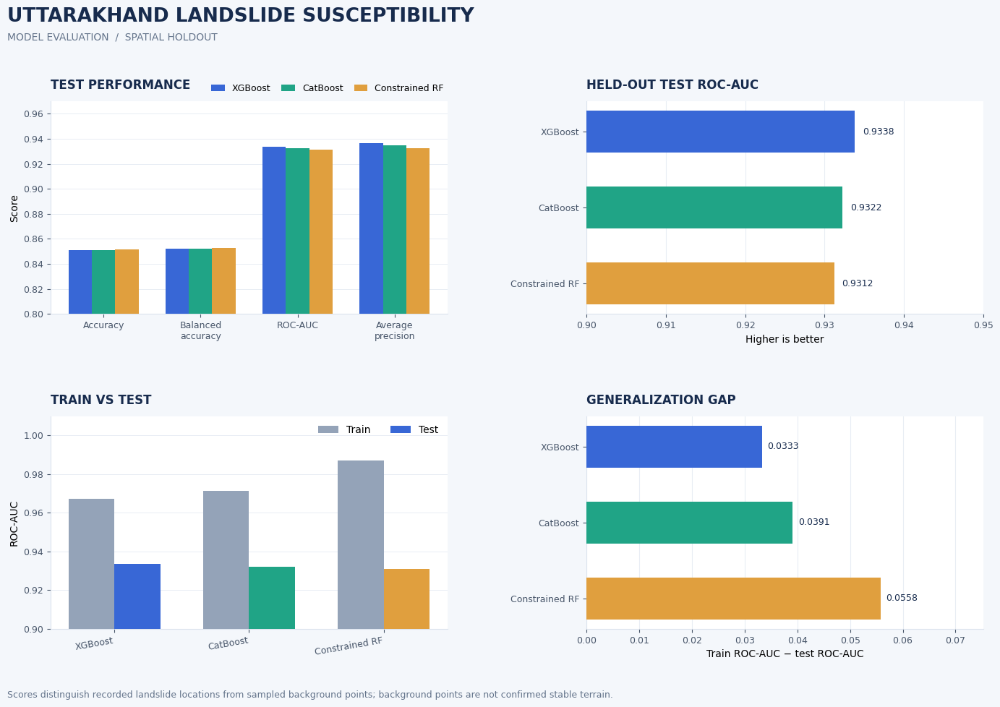

In [18]:
# @title

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# Uses your existing performance_report DataFrame

model_order = ["XGBoost", "CatBoost", "Constrained RF"]
colors = {
    "XGBoost": "#3867D6",
    "CatBoost": "#20A486",
    "Constrained RF": "#E09F3E",
}

report = performance_report.copy()

test_data = (
    report[report["Dataset"] == "Test"]
    .set_index("Model")
    .reindex(model_order)
)

train_data = (
    report[report["Dataset"] == "Train"]
    .set_index("Model")
    .reindex(model_order)
)

metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "ROC-AUC",
    "Average Precision",
]

# Clean, spacious styling
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    gridspec_kw={"height_ratios": [1, 1]},
)
fig.patch.set_facecolor("#F4F7FB")

for ax in axes.flat:
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#DCE3ED")
    ax.tick_params(colors="#475569", labelsize=9)
    ax.grid(axis="y", color="#E8EDF4", linewidth=0.7)
    ax.set_axisbelow(True)

# ------------------------------------------------
# 1. Test performance: grouped bars
# ------------------------------------------------
ax = axes[0, 0]
x = np.arange(len(metrics))
width = 0.24

for i, model in enumerate(model_order):
    vals = test_data.loc[model, metrics].astype(float).values
    positions = x + (i - 1) * width

    ax.bar(
        positions, vals, width,
        color=colors[model],
        label=model,
        zorder=3,
    )

ax.set_title("TEST PERFORMANCE", loc="left", pad=12, color="#172B4D")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(
    ["Accuracy", "Balanced\naccuracy", "ROC-AUC", "Average\nprecision"]
)
ax.set_ylim(0.80, 0.97)
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.legend(
    frameon=False,
    fontsize=9,
    ncol=3,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.02),
    borderaxespad=0,
    handlelength=1.5,
    columnspacing=1.2,
)
ax.grid(axis="x", visible=False)

# ------------------------------------------------
# 2. Test ROC-AUC: horizontal bars with labels
# ------------------------------------------------
ax = axes[0, 1]
auc_values = test_data["ROC-AUC"].astype(float).values
y = np.arange(len(model_order))

bars = ax.barh(
    y,
    auc_values,
    color=[colors[m] for m in model_order],
    height=0.55,
    zorder=3,
)

for bar, val in zip(bars, auc_values):
    ax.text(
        val + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.4f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#172B4D",
    )

ax.set_yticks(y)
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(0.90, 0.95)
ax.set_title("HELD-OUT TEST ROC-AUC", loc="left", pad=12, color="#172B4D")
ax.set_xlabel("Higher is better")
ax.grid(axis="x", color="#E8EDF4")
ax.grid(axis="y", visible=False)

# ------------------------------------------------
# 3. Train vs test ROC-AUC
# ------------------------------------------------
ax = axes[1, 0]
x = np.arange(len(model_order))
width = 0.34

train_auc = train_data["ROC-AUC"].astype(float).values
test_auc = test_data["ROC-AUC"].astype(float).values

ax.bar(
    x - width / 2, train_auc, width,
    label="Train", color="#94A3B8", zorder=3,
)
ax.bar(
    x + width / 2, test_auc, width,
    label="Test",
    color=[colors[m] for m in model_order],
    zorder=3,
)

ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=10, ha="right")
ax.set_ylim(0.90, 1.01)
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.set_title("TRAIN VS TEST", loc="left", pad=12, color="#172B4D")
ax.set_ylabel("ROC-AUC")
ax.legend(frameon=False, ncol=2, loc="upper right")
ax.grid(axis="x", visible=False)

# ------------------------------------------------
# 4. Generalization gap
# ------------------------------------------------
ax = axes[1, 1]
gaps = train_auc - test_auc

bars = ax.barh(
    y,
    gaps,
    color=[colors[m] for m in model_order],
    height=0.55,
    zorder=3,
)

for bar, val in zip(bars, gaps):
    ax.text(
        val + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.4f}",
        va="center",
        fontsize=9,
        color="#172B4D",
    )

ax.set_yticks(y)
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(0, max(gaps) * 1.35)
ax.set_xlabel("Train ROC-AUC − test ROC-AUC")
ax.set_title("GENERALIZATION GAP", loc="left", pad=12, color="#172B4D")
ax.grid(axis="x", color="#E8EDF4")
ax.grid(axis="y", visible=False)

# ------------------------------------------------
# Dashboard heading and concise footer
# ------------------------------------------------
fig.suptitle(
    "UTTARAKHAND LANDSLIDE SUSCEPTIBILITY",
    x=0.06, y=0.98,
    ha="left",
    fontsize=19,
    fontweight="bold",
    color="#172B4D",
)

fig.text(
    0.06, 0.935,
    "MODEL EVALUATION  /  SPATIAL HOLDOUT",
    fontsize=10,
    color="#64748B",
)

fig.text(
    0.06, 0.025,
    "Scores distinguish recorded landslide locations from sampled background points; "
    "background points are not confirmed stable terrain.",
    fontsize=9,
    color="#64748B",
)

fig.subplots_adjust(
    left=0.10,
    right=0.96,
    top=0.85,
    bottom=0.12,
    hspace=0.48,
    wspace=0.35,
)

plt.show()


In [19]:
# @title

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import pandas as pd

categorical_features = ["land_cover"]

numeric_features = [
    "elevation",
    "slope",
    "aspect",
    "profile_curvature",
    "plan_curvature",
    "distance_to_road",
    "distance_to_river",
]

preprocessor = ColumnTransformer([
    (
        "land_cover",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
    ("numeric", "passthrough", numeric_features),
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.03,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    )),
])

groups_train = spatial_df.loc[
    X_train.index, "spatial_group"
]

cv = GroupKFold(n_splits=5)

scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "balanced_accuracy": "balanced_accuracy",
        "average_precision": "average_precision",
    },
    n_jobs=1,
    return_train_score=True,
)

cv_report = pd.DataFrame({
    "Fold": range(1, 6),
    "Train ROC-AUC": scores["train_roc_auc"],
    "Validation ROC-AUC": scores["test_roc_auc"],
    "Balanced Accuracy": scores["test_balanced_accuracy"],
    "Average Precision": scores["test_average_precision"],
})

display(cv_report.round(4))

print("\nMean spatial CV performance:")
display(
    cv_report.drop(columns="Fold").agg(["mean", "std"]).round(4)
)


,Fold,Train ROC-AUC,Validation ROC-AUC,Balanced Accuracy,Average Precision
0,1,0.9694,0.9489,0.8773,0.9404
1,2,0.9701,0.9435,0.8644,0.9406
2,3,0.9693,0.9474,0.8794,0.9440
3,4,0.9693,0.9527,0.8703,0.9522
4,5,0.9681,0.9559,0.8887,0.9501



Mean spatial CV performance:


,Train ROC-AUC,Validation ROC-AUC,Balanced Accuracy,Average Precision
mean,0.9693,0.9497,0.8760,0.9455
std,0.0007,0.0048,0.0092,0.0054
